<small>Dataset: Churn_Modelling.csv</small>

# Q30. Bank Churn ANN

Build and train a small feed-forward binary classification neural network.


## Question from Classroom

Bank Customer Churn Prediction Using ANN 
Problem statement: Develop a neural network classifier to predict whether a bank customer 
will leave within the period represented by the dataset. 
Dataset: Bank Customer Churn Modeling — Kaggle 
Tasks to be performed: 
1. Load the dataset and inspect its features and target variable. 
2. Separate the input features from the churn label. 
3. Encode categorical variables and scale numerical features using training data. 
4. Divide the dataset into training and testing sets. 
5. Build an ANN using an input layer, at least one hidden layer and an output layer. 
6. Compile and train the model using suitable loss and optimization functions. 
7. Predict churn labels and display accuracy and the confusion matrix.


## Understand before coding

Read X/y -> fit/validation/test split -> one-hot encode -> training-only imputation and scaling -> build -> compile -> train -> threshold probabilities -> evaluate.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl tensorflow
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load the dataset and inspect its features and target variable.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

import tensorflow as tf
from sklearn.preprocessing import StandardScaler
tf.keras.utils.set_random_seed(42)
df=pd.read_csv("data/Churn_Modelling.csv").dropna(subset=["Exited"])

print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)


Shape: (10000, 14)
   RowNumber  CustomerId  ...  EstimatedSalary  Exited
0          1    15634602  ...        101348.88       1
1          2    15647311  ...        112542.58       0
2          3    15619304  ...        113931.57       1
3          4    15701354  ...         93826.63       0
4          5    15737888  ...         79084.10       0

[5 rows x 14 columns]
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    100

## Task 2. Separate the input features from the churn label.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
X=df.drop(columns=["RowNumber","CustomerId","Surname","Exited"])
y=df["Exited"].astype(int)
print("Class counts:",y.value_counts().to_dict())


Class counts: {0: 7963, 1: 2037}


## Task 3. Encode categorical variables and scale numerical features using training data.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
def prepare_features(X_fit,X_valid,X_test):
    # Learn category columns from fitting rows; align validation and test to them.
    X_fit = pd.get_dummies(X_fit,dtype=int)
    X_valid = pd.get_dummies(X_valid,dtype=int).reindex(columns=X_fit.columns,fill_value=0)
    X_test = pd.get_dummies(X_test,dtype=int).reindex(columns=X_fit.columns,fill_value=0)
    medians = X_fit.median()
    X_fit = X_fit.fillna(medians)
    X_valid = X_valid.fillna(medians)
    X_test = X_test.fillna(medians)
    
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(X_fit).astype("float32")
    valid_scaled = scaler.transform(X_valid).astype("float32")
    test_scaled = scaler.transform(X_test).astype("float32")
    print("Fit rows:",len(X_fit),"Validation rows:",len(X_valid),"Test rows:",len(X_test))
    print("Encoded input features:",X_fit.shape[1])
    return train_scaled,valid_scaled,test_scaled


## Task 4. Divide the dataset into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_fit,X_valid,y_fit,y_valid=train_test_split(X_train,y_train,test_size=0.2,random_state=42,stratify=y_train)

train_scaled,valid_scaled,test_scaled=prepare_features(X_fit,X_valid,X_test)


Fit rows: 6400 Validation rows: 1600 Test rows: 2000
Encoded input features: 13


## Task 5. Build an ANN using an input layer, at least one hidden layer and an output layer.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(train_scaled.shape[1],)),
    tf.keras.layers.Dense(16,activation="relu"),
    tf.keras.layers.Dense(8,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid")
])


## Task 6. Compile and train the model using suitable loss and optimization functions.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
model.summary()
history = model.fit(train_scaled,y_fit,epochs=15,batch_size=32,
                    validation_data=(valid_scaled,y_valid),verbose=0)
print("Training completed: 15 epochs")


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 369 (1.44 KB)
 Trainable params: 369 (1.44 KB)
 Non-trainable params: 0 (0.00 B)
Training completed: 15 epochs


## Task 7. Predict churn labels and display accuracy and the confusion matrix.

This block implements the task above. Variables from earlier blocks are reused.


Accuracy: 0.8625
Confusion matrix:
 [[1537   56]
 [ 219  188]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.77      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000

   Actual  Probability of class 1  Predicted
0       0                0.028346          0
1       0                0.064150          0
2       0                0.050872          0
3       0                0.097812          0
4       0                0.111124          0
5       0                0.300534          0
6       0                0.031958          0
7       0                0.143727          0
8       0                0.646187          1
9       0                0.030028          0


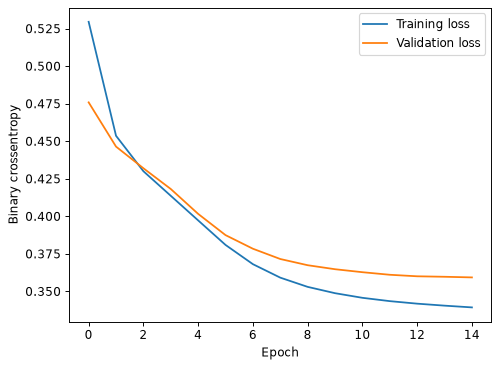

In [7]:
probability = model.predict(test_scaled,verbose=0).ravel()
prediction = (probability >= 0.5).astype(int)
print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=[0,1]))
print(classification_report(y_test,prediction,zero_division=0))
print(pd.DataFrame({"Actual":np.asarray(y_test),"Probability of class 1":probability,
                    "Predicted":prediction}).head(10))
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary crossentropy"); plt.legend(); plt.show()


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. What is an ANN?**

A network of units applying weighted sums, biases and nonlinear activation functions to learn a mapping from inputs to outputs.

**14. Describe the architecture here.**

The input width equals the encoded feature count, followed by Dense layers with 16 ReLU units, 8 ReLU units and one sigmoid output unit.

**15. Why ReLU?**

ReLU(x)=max(0,x). It introduces nonlinearity so multiple layers can model more than a single linear transformation.

**16. Why one sigmoid output?**

sigmoid(z)=1/(1+exp(-z)) gives a value between 0 and 1 for binary class 1. The default decision threshold is 0.5.

**17. Why binary crossentropy?**

For a binary target it penalizes incorrect probability estimates: -[y*log(p)+(1-y)*log(1-p)], averaged over examples.

**18. What does Adam do?**

It is a gradient-based optimizer with adaptive per-parameter update scaling and momentum-like estimates.

**19. What is an epoch and batch?**

An epoch is one complete pass through training examples. A batch is the group used for one gradient update; here batch_size=32.

**20. What is backpropagation?**

Using the chain rule to calculate loss gradients through network layers so the optimizer can update weights.

**21. Why separate fitting, validation and test sets?**

Fit weights on fitting rows, monitor learning on validation rows, and reserve the test split for final evaluation. Scaling and category layout are learned from fitting rows only.

**22. How can overfitting appear?**

Training loss decreases while validation loss worsens. Possible controls include fewer epochs, a smaller network, regularization, dropout or early stopping.

**23. Does the model guarantee a useful classifier?**

No. Compare the actual per-class results against a simple baseline, especially for imbalanced labels. A majority-class prediction can have deceptively high accuracy.

**24. Complexity?**

Work is roughly proportional to epochs times training examples times the number of weights, with architecture and implementation affecting runtime.

**25. Which target and identifiers are used?**

Exited is y: 1 means left, 0 means stayed. RowNumber, CustomerId and Surname are dropped. Geography and Gender are one-hot encoded.

**26. Why is churn imbalance relevant?**

A high stay rate can make a model that predicts everyone stays appear accurate. Inspect class-1 recall/F1 and the confusion matrix.


### Task-to-code map

- **Block 1:** Load the dataset and inspect its features and target variable.
- **Block 2:** Separate the input features from the churn label.
- **Block 3:** Encode categorical variables and scale numerical features using training data.
- **Block 4:** Divide the dataset into training and testing sets.
- **Block 5:** Build an ANN using an input layer, at least one hidden layer and an output layer.
- **Block 6:** Compile and train the model using suitable loss and optimization functions.
- **Block 7:** Predict churn labels and display accuracy and the confusion matrix.
